In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

In [2]:
def insert_ma(ax, pos: tuple[float], size: tuple[float], alpha0 = 0.75, alpha1 = 0.25):
    """
    """
    
    ax_i = ax.inset_axes([*pos, *size])
    ax_i.axis('equal')
    ax_i.axis('off')
    ax_i.set_xlim([-1, 1])
    ax_i.set_ylim([-1, 1])
    
    x = np.linspace(0, 2 * np.pi, 100)
    y = np.sin(x)
    z = np.cos(x)
    
    ax_i.plot(y, z, lw = 1.0, color = plots.colours.H2, alpha = alpha0, clip_on = False)
    ax_i.fill_between(y, z, edgecolor = 'None', facecolor = plots.colours.H1, alpha = alpha1)
    
    return ax_i

from typing import Dict, List
def annotate_ma(ax, annotations: Dict[str, np.ndarray], cut_a: List[str], cut_b: List[str], col_a = None, col_b = None):
    """
    """
    
    for name in annotations:
        xy, ha, va = annotations[name]
        alpha_a, color = (1.0, col_a) if name not in cut_a else (0.5, plots.colours.H2)
        if color is None:
            color = plots.colours.H2
        
        ax.annotate(name, xy = (0, 0), xytext = tuple(xy), ha = ha, va = va, color = color, alpha = alpha_a)
    
    for i, X in enumerate(annotations):
        for j, Y in enumerate(annotations):
            if i <= j: continue
            
            xx, _, _ = annotations[X]
            yy, _, _ = annotations[Y]
            
            alpha_a, ls, color = (1.0, '-', col_b) if (X not in cut_a) and (Y not in cut_a) and (f'{X}-{Y}' not in cut_b) and (f'{Y}-{X}' not in cut_b) else (0.5, '--', plots.colours.H2)
            if color is None:
                color = plots.colours.H2
            
            xx, yy = 0.9 * xx, 0.9 * yy
            
            ax.plot([xx[0], yy[0]], [xx[1], yy[1]], linewidth = 0.5, color = color, alpha = alpha_a, linestyle = ls)

/var/folders/b4/qysvl6jd4995kp_qql3yj3880000gn/T/ipykernel_90000/3436006514.py:54: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  deltas[:,i] = within - baseline
/var/folders/b4/qysvl6jd4995kp_qql3yj3880000gn/T/ipykernel_90000/3436006514.py:123: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  deltas[:,i] = within - baseline
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data

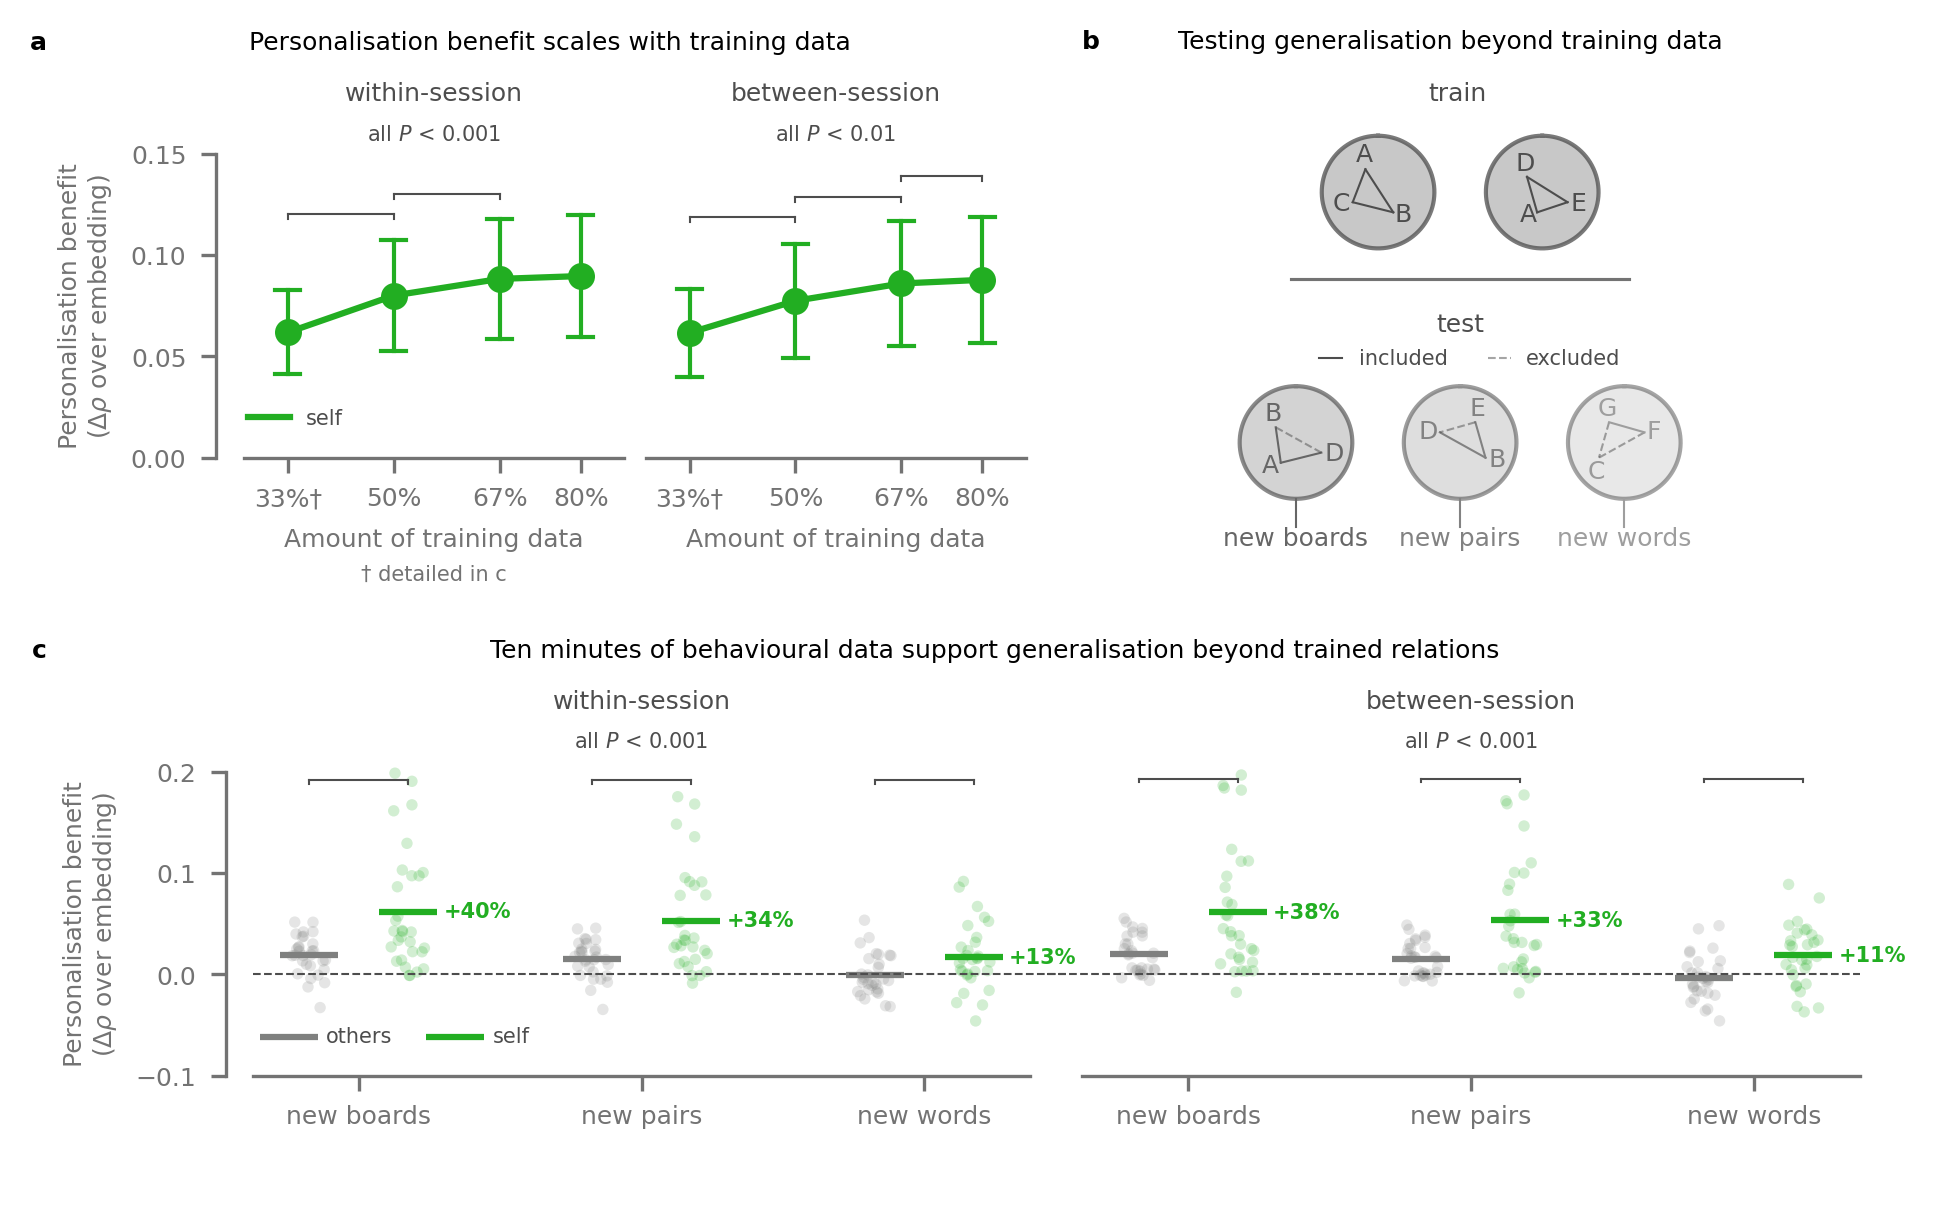

In [3]:
hypothesis_test = 'sign'
hypothesis_alternative = 'greater'
hypothesis_method = 'holm'
hypothesis_se = 'within'
show_pct = True

run = 0
exp = 1
mod = 'glove'

runs_labels = ['33%†', '50%', '67%', '80%']
runs_xs = [0.33, 0.50, 0.67, 0.80]
runs = [1, 2, 3, 4]

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

cols2 = np.array([
    plots.colours.CM_RDM_CL(0.00),
    plots.colours.CM_RDM_CL(0.20),
    plots.colours.CM_RDM_CL(0.40)
])

fig, ax = plt.subplots(figsize = (6.4, 4.0), dpi = 300)

# remove axis
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')

'''
panel A
'''

# as a function of training data
ax3 = ax.inset_axes([0.035, 0.67, 0.22, 0.28])

P = ''
deltas = np.zeros((30, len(runs)))
offset = 0.0
seoff = 0.02
X_jitter = 0.125 * np.random.uniform(low = -1.0, high = 1.0, size = (deltas.shape[0],))

for i, run in enumerate(runs):
    out = torch.load(f'../data/ds-exp1/derivatives/run-{run:03d}/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
    rho = out[f'{P}rho_BZ']
    eye = torch.eye(rho.shape[0], dtype = torch.bool)
    within = rho[eye].squeeze()
    between = rho[eye == False].view(eye.shape[0], eye.shape[0] - 1).mean(1)
    baseline = out[f'{P}rho_BE'][...,0][eye]
    deltas[:,i] = within - baseline
    
    mu = deltas[:,i].mean()
    se = model.stats.bootstrap_se(deltas[:,i])
    x_i = runs_xs[i] + X_jitter
    
    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se

# plot trajectory
mu = deltas.mean(0)
ax3.plot(runs_xs, mu, color = cols[2], label = 'self')

# plot individual points
for i, _ in enumerate(runs):
    mu = deltas[:,i].mean()
    se = model.stats.bootstrap_se(deltas[:,i])
    x_i = runs_xs[i] + X_jitter
    
    col_se = cols[2]
    ii = runs_xs[i]
    ax3.plot([ii, ii], [mu - 1.96 * se, mu + 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
    ax3.plot([ii-seoff,ii+seoff], [mu - 1.96 * se, mu - 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
    ax3.plot([ii-seoff,ii+seoff], [mu + 1.96 * se, mu + 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
    ax3.scatter([ii], [mu], color = cols[2], marker = 'o', s = 30, zorder = 2, clip_on = False)

design = [(1, 0), (2, 1), (3, 2)]
group = model.stats.sample_tests(deltas.T, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(deltas.T, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig2/a_wthn_group.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig2/a_wthn_pairs.csv')

# significance
count = 0.0
gain = 0.01
min_p = 0.0

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        if p_i > min_p:
            min_p = p_i
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = offset + count * gain
        iii, jjj = runs_xs[ii], runs_xs[jj]
        
        ax3.plot([iii, jjj], [yy, yy], color = plots.colours.H2, linewidth = 0.5)
        ax3.plot([iii, iii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5)
        ax3.plot([jjj, jjj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5)
        count += 1

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
ax3.annotate(f'all {rep_p}', xy = (0, 0), xytext = (0.565, 0.16), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2, annotation_clip = False)

# as a function of training data
ax4 = ax.inset_axes([0.2675, 0.67, 0.22, 0.28])

deltas = np.zeros((30, len(runs)))
offset = 0.0

for i, run in enumerate(runs):
    out = torch.load(f'../data/ds-exp1/derivatives/run-{run:03d}/tasks/task-macross_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
    rho = out[f'{P}rho_BZ']
    eye = torch.eye(rho.shape[0], dtype = torch.bool)
    within = rho[eye].squeeze()
    between = rho[eye == False].view(eye.shape[0], eye.shape[0] - 1).mean(1)
    baseline = out[f'{P}rho_BE'][...,0][eye]
    deltas[:,i] = within - baseline
    
    mu = deltas[:,i].mean()
    se = model.stats.bootstrap_se(deltas[:,i])
    x_i = runs_xs[i] + X_jitter
    
    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se

# plot trajectory
mu = deltas.mean(0)
ax4.plot(runs_xs, mu, color = cols[2])

# plot individual points
for i, _ in enumerate(runs):
    mu = deltas[:,i].mean()
    se = model.stats.bootstrap_se(deltas[:,i])
    x_i = i + X_jitter
    
    col_se = cols[2]
    ii = runs_xs[i]
    ax4.plot([ii, ii], [mu - 1.96 * se, mu + 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
    ax4.plot([ii-seoff,ii+seoff], [mu - 1.96 * se, mu - 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
    ax4.plot([ii-seoff,ii+seoff], [mu + 1.96 * se, mu + 1.96 * se], lw = 1, color = col_se, zorder = 1, clip_on = False)
    ax4.scatter([ii], [mu], color = cols[2], marker = 'o', s = 30, zorder = 2, clip_on = False)

design = [(1, 0), (2, 1), (3, 2)]
group = model.stats.sample_tests(deltas.T, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(deltas.T, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig2/a_btwn_group.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig2/a_btwn_pairs.csv')

# significance
count = 0.0
min_p = 0.0

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        if p_i > min_p:
            min_p = p_i
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = offset + count * gain
        iii, jjj = runs_xs[ii], runs_xs[jj]
        
        ax4.plot([iii, jjj], [yy, yy], color = plots.colours.H2, linewidth = 0.5)
        ax4.plot([iii, iii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5)
        ax4.plot([jjj, jjj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5)
        count += 1

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
ax4.annotate(f'all {rep_p}', xy = (0, 0), xytext = (0.565, 0.16), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2, annotation_clip = False)

# legend
ax3.legend(
    bbox_to_anchor = (0.31, 0.225),
    frameon = False,
    ncols = 2,
    fontsize = 5,
    labelcolor = plots.colours.H2
)

for i, ax_i in enumerate([ax3, ax4]):
    xlabels = runs_labels# if i == 0 else []
    xlab = fr'Amount of training data'# if i == 0 else ''
    yticks = [0.0, 0.05, 0.1, 0.15] if i == 0 else []
    ylab = 'Personalisation benefit\n' + fr'($\Delta\rho$ over embedding)' if i == 0 else ''
    title = fr'within-session' if i == 0 else fr'between-session'
    
    ax_i.annotate(title, xy = (0, 0), xytext = (0.565, 0.18), color = plots.colours.H2, ha = 'center', va = 'center', fontsize = 6, annotation_clip = False)
    
    ax_i.set_ylim([0.0, 0.15])
    ax_i.set_yticks(yticks)
    ax_i.set_ylabel(ylab)
    ax_i.set_xlim([0.26, 0.87])
    ax_i.set_xticks(runs_xs)
    ax_i.set_xticklabels(xlabels)
    ax_i.set_xlabel(xlab)
    
    sns.despine(ax = ax_i)
    
    if i == 1:
        ax_i.spines['left'].set_visible(False)
    
    if i == 0:
        ax_i.spines['left'].set_position(('axes', -0.075))
        ax_i.annotate('† detailed in c', xy = (0, 0), xytext = (0.565, -0.0575), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H3, annotation_clip = False)

'''
panel B
'''

# add generalisation
ax12 = ax.inset_axes([0.525, 0.67, 0.475, 0.35])
ax12.axis('off')
ax12.set_xlim([-1, 1.0])
ax12.set_ylim([-1, 0.8])

# insert training and testing ma
ax13 = insert_ma(ax12, (0.1, 0.55), (0.5, 0.3))
ax14 = insert_ma(ax12, (0.3, 0.55), (0.5, 0.3))

#ax15 = insert_ma(ax12, (-0.15, -0.11), (0.5, 0.3), alpha0 = 0.65, alpha1 = 0.2)
#ax16 = insert_ma(ax12, (0.2, -0.11), (0.5, 0.3), alpha0 = 0.55, alpha1 = 0.15)
#ax17 = insert_ma(ax12, (0.55, -0.11), (0.5, 0.3), alpha0 = 0.50, alpha1 = 0.1)
ax15 = insert_ma(ax12, (0.0, -0.11), (0.5, 0.3), alpha0 = 0.65, alpha1 = 0.2)
ax16 = insert_ma(ax12, (0.2, -0.11), (0.5, 0.3), alpha0 = 0.55, alpha1 = 0.15)
ax17 = insert_ma(ax12, (0.4, -0.11), (0.5, 0.3), alpha0 = 0.50, alpha1 = 0.1)

annotate_ma(
    ax13, 
    dict(
        A = (np.array([-0.25, 0.45]), 'center', 'bottom'), 
        B = (np.array([0.3, -0.4]), 'left', 'center'), 
        C = (np.array([-0.5, -0.2]), 'right', 'center')
    ),
    [],
    []
)

annotate_ma(
    ax14, 
    dict(
        A = (np.array([-0.1, -0.4]), 'right', 'center'), 
        D = (np.array([-0.3, 0.3]), 'center', 'bottom'), 
        E = (np.array([0.5, -0.2]), 'left', 'center')
    ),
    [],
    []
)

annotate_ma(
    ax15, 
    dict(
        A = (np.array([-0.3, -0.4]), 'right', 'center'), 
        B = (np.array([-0.4, 0.3]), 'center', 'bottom'), 
        D = (np.array([0.5, -0.2]), 'left', 'center')
    ),
    [],
    ['B-D'],
    col_a = cols2[0],
    col_b = cols2[0]
)

annotate_ma(
    ax16, 
    dict(
        B = (np.array([0.5, -0.3]), 'left', 'center'), 
        D = (np.array([-0.4, 0.2]), 'right', 'center'), 
        E = (np.array([0.3, 0.4]), 'center', 'bottom')
    ),
    [],
    ['D-E'],
    col_a = cols2[1],
    col_b = cols2[1]
)

annotate_ma(
    ax17, 
    dict(
        C = (np.array([-0.5, -0.3]), 'center', 'top'), 
        F = (np.array([0.4, 0.2]), 'left', 'center'), 
        G = (np.array([-0.3, 0.4]), 'center', 'bottom')
    ),
    ['C'],
    [],
    col_a = cols2[2],
    col_b = cols2[2]
)

# add set labels
ax14.annotate('train', xy = (0, 0), xytext = (-1.5, 1.75), fontsize = 6, color = plots.colours.H2, ha = 'center', va = 'center', annotation_clip = False)
ax16.annotate('test', xy = (0, 0), xytext = (0.0, 2.10), fontsize = 6, color = plots.colours.H2, ha = 'center', va = 'center', annotation_clip = False)

# add inc/exc legend
ax16.plot([-2.5, -2.1], [1.50, 1.50], linewidth = 0.5, color = plots.colours.H2, clip_on = False)
ax16.annotate('included', xy = (0, 0), xytext = (-1.0, 1.50), fontsize = 5, color = plots.colours.H2, ha = 'center', va = 'center', annotation_clip = False)

ax16.plot([0.5, 0.9], [1.50, 1.50], linewidth = 0.5, linestyle = '--', color = plots.colours.H2, alpha = 0.5, clip_on = False)
ax16.annotate('excluded', xy = (0, 0), xytext = (2.0, 1.50), fontsize = 5, color = plots.colours.H2, ha = 'center', va = 'center', annotation_clip = False)

# type legend
ax15.annotate('new boards', xy = (0, 0), xytext = (0.0, -1.7), ha = 'center', va = 'center', color = cols2[0], annotation_clip = False)
ax15.plot([0.0, 0.0], [-1, -1.5], linewidth = 0.5, color = cols2[0], clip_on = False)

ax16.annotate('new pairs', xy = (0, 0), xytext = (0.0, -1.7), ha = 'center', va = 'center', color = cols2[1], annotation_clip = False)
ax16.plot([0.0, 0.0], [-1, -1.5], linewidth = 0.5, color = cols2[1], clip_on = False)

ax17.annotate('new words', xy = (0, 0), xytext = (0.0, -1.7), ha = 'center', va = 'center', color = cols2[2], annotation_clip = False)
ax17.plot([0.0, 0.0], [-1, -1.5], linewidth = 0.5, color = cols2[2], clip_on = False)

# add seperator
ax16.plot([-3.0, 3.0], [2.90, 2.90], lw = 0.75, ls = '-', color = plots.colours.H3, clip_on = False)

'''
panel C
'''

Ps = ['', 'pns_', 'uns_']
run = 1

# within-session
values = np.zeros((len(Ps) * 3, 30))
deltas = np.zeros((len(Ps) * 2, 30))

R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

for i, P in enumerate(Ps):
    R_base = R[f'{P}rho_BE'].squeeze().cpu().numpy().diagonal()
    R_indiv = R[f'{P}rho_BZ'].cpu().numpy().diagonal().squeeze()
    R_group = R[f'{P}rho_BZ'].cpu().numpy()
    R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

    R_a = np.array([R_base, R_group, R_indiv])
    R_b = R_a[1:] - R_a[0]
    
    deltas[i*2,:] = R_b[0,:]
    deltas[i*2+1] = R_b[1,:]
    
    values[i*3,:] = R_a[0]
    values[i*3+1,:] = R_a[1]
    values[i*3+2,:] = R_a[2]

#ax5 = ax.inset_axes([0.04, 0.11, 0.45, 0.25])
ax5 = ax.inset_axes([0.04, 0.1, 0.45, 0.28])

offset = 0

for i, R_i in enumerate(deltas):
    x_off = 0.15 * 2 * (i % 2 - 0.5)
    
    mu = R_i.mean()
    se = model.stats.bootstrap_se(R_i)
    x_i = i + X_jitter - x_off
    
    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se
    
    label = None
    if i == 0:
        label = 'others'
    elif i == 1:
        label = 'self'
    ax5.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i % 2 + 1], s = 30, alpha = 0.2, clip_on = False)
    ax5.scatter([i - x_off], [mu], color = cols[i % 2 + 1], label = label, marker = '_', s = 200, clip_on = False, zorder = 2)

ax5.patch.set_facecolor('None')
sns.despine(ax = ax5)

# significance
count = 0.0
gain = 0.015
min_p = 0.0

design = [(1, 0), (3, 2), (5, 4)]
group = model.stats.sample_tests(deltas, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(deltas, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig2/c_wthn_group.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig2/c_wthn_pairs-0.csv')

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        sig_off = np.abs(x_off)
        
        if p_i > min_p:
            min_p = p_i
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = 0.11 + offset + count * gain
        ax5.plot([ii-sig_off, jj+sig_off], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        ax5.plot([ii-sig_off, ii-sig_off], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        ax5.plot([jj+sig_off, jj+sig_off], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
ax5.annotate(f'all {rep_p}', xy = (0, 0), xytext = (2.5, 0.23), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

design = [
    (1, 0), (2, 0), (2, 1), # new boards: G > B; I > B; I > G
    (4, 3), (5, 3), (5, 4), # new pairs:  G > B; I > B; I > G
    (7, 6), (8, 6), (8, 7)  # new words:  G > B; I > B; I > G
]
pairwise = model.stats.pairwise_tests(values, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(pairwise, './deliverable/csv/fig2/c_wthn_pairs-1.csv')

if show_pct:
    #xoff, yoff = 0.0, 0.02
    xoff, yoff = 0.25, 0.0
    fs, fw = 5, 'semibold'
    bbs, bbc, bba = 'square,pad=.1', 'white', 0.4
    
    mu = int(round(pairwise[1]['pct_mu']))
    y = pairwise[1]['mu']
    ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (1 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
    #ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (1 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))
    
    mu = int(round(pairwise[4]['pct_mu']))
    y = pairwise[4]['mu']
    ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (3 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
    #ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (3 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))
    
    mu = int(round(pairwise[7]['pct_mu']))
    y = pairwise[7]['mu']
    ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (5 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
    #ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (5 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))
    
# between-session
values = np.zeros((len(Ps) * 3, 30))
deltas = np.zeros((len(Ps) * 2, 30))

R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-macross_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

for i, P in enumerate(Ps):
    R_base = R[f'{P}rho_BE'].squeeze().cpu().numpy().diagonal()
    R_indiv = R[f'{P}rho_BZ'].cpu().numpy().diagonal().squeeze()
    R_group = R[f'{P}rho_BZ'].cpu().numpy()
    R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

    R_a = np.array([R_base, R_group, R_indiv])
    R_b = R_a[1:] - R_a[0]
    
    deltas[i*2,:] = R_b[0,:]
    deltas[i*2+1] = R_b[1,:]
    
    values[i*3,:] = R_a[0]
    values[i*3+1,:] = R_a[1]
    values[i*3+2,:] = R_a[2]

#ax6 = ax.inset_axes([0.52, 0.11, 0.45, 0.25])
ax6 = ax.inset_axes([0.52, 0.1, 0.45, 0.28])

offset = 0

for i, R_i in enumerate(deltas):
    x_off = 0.15 * 2 * (i % 2 - 0.5)
    
    mu = R_i.mean()
    se = model.stats.bootstrap_se(R_i)
    x_i = i + X_jitter - x_off
    
    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se
    
    ax6.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i % 2 + 1], s = 30, alpha = 0.2, clip_on = False)
    ax6.scatter([i - x_off], [mu], color = cols[i % 2 + 1], marker = '_', s = 200, clip_on = False, zorder = 2)

ax6.patch.set_facecolor('None')
sns.despine(ax = ax6)

design = [(1, 0), (3, 2), (5, 4)]
group = model.stats.sample_tests(deltas, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(deltas, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig2/c_btwn_group.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig2/c_btwn_pairs-0.csv')

# significance
count = 0.0
min_p = 0.0

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        sig_off = np.abs(x_off)
        
        if p_i > min_p:
            min_p = p_i
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = 0.11 + offset + count * gain
        ax6.plot([ii-sig_off, jj+sig_off], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        ax6.plot([ii-sig_off, ii-sig_off], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        ax6.plot([jj+sig_off, jj+sig_off], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
ax6.annotate(f'all {rep_p}', xy = (0, 0), xytext = (2.5, 0.23), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

design = [
    (1, 0), (2, 0), (2, 1), # new boards: G > B; I > B; I > G
    (4, 3), (5, 3), (5, 4), # new pairs:  G > B; I > B; I > G
    (7, 6), (8, 6), (8, 7)  # new words:  G > B; I > B; I > G
]
pairwise = model.stats.pairwise_tests(values, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(pairwise, './deliverable/csv/fig2/c_btwn_pairs-1.csv')

if show_pct:
    #xoff, yoff = 0.0, 0.02
    xoff, yoff = 0.25, 0.0
    fs, fw = 5, 'semibold'
    bbs, bbc, bba = 'square,pad=.1', 'white', 0.4
    
    mu = int(round(pairwise[1]['pct_mu']))
    y = pairwise[1]['mu']
    ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (1 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
    #ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (1 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))
    
    mu = int(round(pairwise[4]['pct_mu']))
    y = pairwise[4]['mu']
    ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (3 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
    #ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (3 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))
    
    mu = int(round(pairwise[7]['pct_mu']))
    y = pairwise[7]['mu']
    ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (5 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
    #ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (5 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))
    
# legend
ax5.legend(
    bbox_to_anchor = (0.38, 0.225),
    frameon = False,
    ncols = 2,
    fontsize = 5,
    labelcolor = plots.colours.H2
)
    
for i, ax_i in enumerate([ax5, ax6]):
    yticks = [-0.1, 0.0, 0.1, 0.2] if i == 0 else []
    ylab = 'Personalisation benefit\n' + fr'($\Delta\rho$ over embedding)' if i == 0 else ''
    xticks = ['new boards', 'new pairs', 'new words']# if i == 0 else []
    title = fr'within-session' if i == 0 else 'between-session'
    
    ax_i.annotate(title, xy = (0, 0), xytext = (2.5, 0.27), ha = 'center', va = 'center', color = plots.colours.H2, fontsize = 6, annotation_clip = False)
    
    ax_i.set_yticks(yticks)
    ax_i.set_ylim([-0.1, 0.2])
    ax_i.set_ylabel(ylab)
    ax_i.set_xticks([0.5, 2.5, 4.5])
    ax_i.set_xticklabels(xticks)
    ax_i.set_xlim([-0.25, 5.25])
    
    if i == 1:
        ax_i.spines['left'].set_visible(False)
    
    if i == 0:
        ax_i.spines['left'].set_position(('axes', -0.035))
    
    xext = 0.25
    xmin, xmax = (0.0, xext) if i == 0 else (-xext, 0.0)
    ax_i.plot([-0.25+xmin, 5.25+xmax], [0, 0], linewidth = 0.5, color = plots.colours.H2, linestyle = '--', clip_on = False)        

'''
cosmetics
'''

# colors
for ax_i in [ax3, ax4, ax5, ax6]:
    ax_i.yaxis.label.set_color(plots.colours.H3)
    ax_i.xaxis.label.set_color(plots.colours.H3)
    ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', colors = plots.colours.H3)
    ax_i.spines['bottom'].set_color(plots.colours.H3)
    ax_i.spines['left'].set_color(plots.colours.H3)    

# labels
ax3.annotate('a', xy = (0, 0), xytext = (-0.07, 0.205), ha = 'center', va = 'center', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax3.annotate('Personalisation benefit scales with training data', xy = (0, 0), xytext = (0.75, 0.205), ha = 'center', va = 'center', fontsize = 6, annotation_clip = False)

ax12.annotate('b', xy = (0, 0), xytext = (-1.0, 0.975), ha = 'center', va = 'center', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax12.annotate('Testing generalisation beyond training data', xy = (0, 0), xytext = (-0.125, 0.975), ha = 'center', va = 'center', fontsize = 6, annotation_clip = False)

ax5.annotate('c', xy = (0, 0), xytext = (-1.76, 0.32), ha = 'center', va = 'center', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax5.annotate('Ten minutes of behavioural data support generalisation beyond trained relations', xy = (0, 0), xytext = (5.0, 0.32), ha = 'center', va = 'center', fontsize = 6, annotation_clip = False)

fig.tight_layout()

fig.savefig('./deliverable/png/fig2.png', dpi = 900)
fig.savefig('./deliverable/pdf/fig2.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/fig2.svg', dpi = 900, format = 'svg')

In [30]:
exp = 1
mod = 'glove'
run = 1

for i, P in enumerate(Ps):
    R1 = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
    R2 = torch.load(f'../data/ds-exp{exp}/derivatives/run-100/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

    R1_base = R1[f'{P}rho_BE'].squeeze().cpu().numpy().diagonal()
    R1_indiv = R1[f'{P}rho_BZ'].cpu().numpy().diagonal().squeeze()
    R1_group = R1[f'{P}rho_BZ'].cpu().numpy()
    R1_group = R1_group[np.eye(R1_group.shape[0], dtype = bool) == False].reshape((R1_group.shape[0], R1_group.shape[0] - 1)).mean(-1)
    
    R2_base = R2[f'{P}rho_BE'].squeeze().cpu().numpy().diagonal()
    R2_indiv = R2[f'{P}rho_BZ'].cpu().numpy().diagonal().squeeze()
    R2_group = R2[f'{P}rho_BZ'].cpu().numpy()
    R2_group = R2_group[np.eye(R2_group.shape[0], dtype = bool) == False].reshape((R2_group.shape[0], R2_group.shape[0] - 1)).mean(-1)

    #R_a = np.array([R_base, R_group, R_indiv])
    #R_b = R_a[1:] - R_a[0]
    
    dr1 = (R1_indiv - R1_base)
    dr2 = (R2_indiv - R2_base)
    dr = np.array([dr1, dr2])
    
    pairwise = model.stats.pairwise_tests(dr, [(0, 1)], test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    
    print(dr1.mean(), dr2.mean())
    print(pairwise)

0.06189223 0.040142324
[{'index': (0, 1), 'mu': 0.021749896928668022, 'se': 0.0084751658141613, 'se_method': 'within', 'pct_mu': 54.18198013305664, 'pct_se': 29.03346824645996, 'test': 'sign_rel', 'df': 29, 'statistic': 2.5171610463935523, 'd': 0.46742507815361023, 'p_cor': 0.007359926400735992, 'p_unc': 0.007359926400735992, 'p_method': 'holm'}]
0.053056054 0.033934716
[{'index': (0, 1), 'mu': 0.019121332094073296, 'se': 0.007392941042780876, 'se_method': 'within', 'pct_mu': 56.34741973876953, 'pct_se': 30.019514083862305, 'test': 'sign_rel', 'df': 29, 'statistic': 2.556757202046487, 'd': 0.47477787733078003, 'p_cor': 0.007199928000719993, 'p_unc': 0.007199928000719993, 'p_method': 'holm'}]
0.01723189 0.014558562
[{'index': (0, 1), 'mu': 0.0026733276899904013, 'se': 0.006246437318623066, 'se_method': 'within', 'pct_mu': 18.36256980895996, 'pct_se': 69.47491455078125, 'test': 'sign_rel', 'df': 29, 'statistic': 0.4182855017144856, 'd': 0.07767365872859955, 'p_cor': 0.3377566224337757, '